In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [ ]:
pm25 = pd.read_excel('/content/richmond_pm25_2018_2020.csv.xls')

print(pm25.head())
print(pm25.columns)
pm25.info()
pm25.isnull().sum()

         Date   Time  RICHMOND PM2.5 1h average [µg/m³]
0  01/01/2018  01:00                                3.9
1  01/01/2018  02:00                                5.1
2  01/01/2018  03:00                                4.4
3  01/01/2018  04:00                                3.0
4  01/01/2018  05:00                                1.8
Index(['Date', 'Time', 'RICHMOND PM2.5 1h average [µg/m³]'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16383 entries, 0 to 16382
Data columns (total 3 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Date                               16383 non-null  object 
 1   Time                               16383 non-null  object 
 2   RICHMOND PM2.5 1h average [µg/m³]  14363 non-null  float64
dtypes: float64(1), object(2)
memory usage: 384.1+ KB


,0
Date,0
Time,0
RICHMOND PM2.5 1h average [µg/m³],2020


In [ ]:
pm25 = pm25.rename(columns={
'Date':'date',
'Time':'time',
'RICHMOND PM2.5 1h average [µg/m³]':'pm25'
})

pm25.head()

,date,time,pm25
0,01/01/2018,01:00,3.9
1,01/01/2018,02:00,5.1
2,01/01/2018,03:00,4.4
3,01/01/2018,04:00,3.0
4,01/01/2018,05:00,1.8


In [ ]:
# Create temporary copies of date and time columns to handle '24:00' logic
modified_date = pm25['date'].copy()
modified_time = pm25['time'].copy()

# Identify rows where time is '24:00'
mask_24h = (modified_time == '24:00')

# For these rows, change time to '00:00'
modified_time.loc[mask_24h] = '00:00'

# For these same rows, increment the date by one day
# First, convert the relevant date strings to datetime objects for calculation
dates_to_increment = pd.to_datetime(modified_date.loc[mask_24h], format='%d/%m/%Y')
# Add one day and then convert back to string format 'DD/MM/YYYY' for consistent concatenation
modified_date.loc[mask_24h] = (dates_to_increment + pd.Timedelta(days=1)).dt.strftime('%d/%m/%Y')

# Combine the (potentially modified) date and time strings
combined_datetime_str = modified_date.astype(str) + ' ' + modified_time.astype(str)

# Convert the combined string series to datetime using the correct format for all entries
pm25['datetime'] = pd.to_datetime(combined_datetime_str, format='%d/%m/%Y %H:%M')

pm25.head()

,date,time,pm25,datetime
0,01/01/2018,01:00,3.9,2018-01-01 01:00:00
1,01/01/2018,02:00,5.1,2018-01-01 02:00:00
2,01/01/2018,03:00,4.4,2018-01-01 03:00:00
3,01/01/2018,04:00,3.0,2018-01-01 04:00:00
4,01/01/2018,05:00,1.8,2018-01-01 05:00:00


In [ ]:
pm25['pm25'] = pd.to_numeric(
pm25['pm25'],
errors='coerce'
)

In [ ]:
pm25.isnull().sum()

,0
datetime,0
pm25,2020


In [ ]:
pm25 = pm25[['datetime','pm25']]

pm25.head()

,datetime,pm25
0,2018-01-01 01:00:00,3.9
1,2018-01-01 02:00:00,5.1
2,2018-01-01 03:00:00,4.4
3,2018-01-01 04:00:00,3.0
4,2018-01-01 05:00:00,1.8


In [ ]:
pm25['pm25'] = pm25['pm25'].interpolate()

In [ ]:
pm25.describe()

,datetime,pm25
count,16383,16383.000000
mean,2018-12-08 08:00:00,8.428743
min,2018-01-01 01:00:00,-2.500000
25%,2018-06-20 16:30:00,3.000000
50%,2018-12-08 08:00:00,6.600000
75%,2019-05-27 23:30:00,11.200000
max,2019-11-14 15:00:00,335.400000
std,NaN,11.814309


In [ ]:
import matplotlib.pyplot as plt

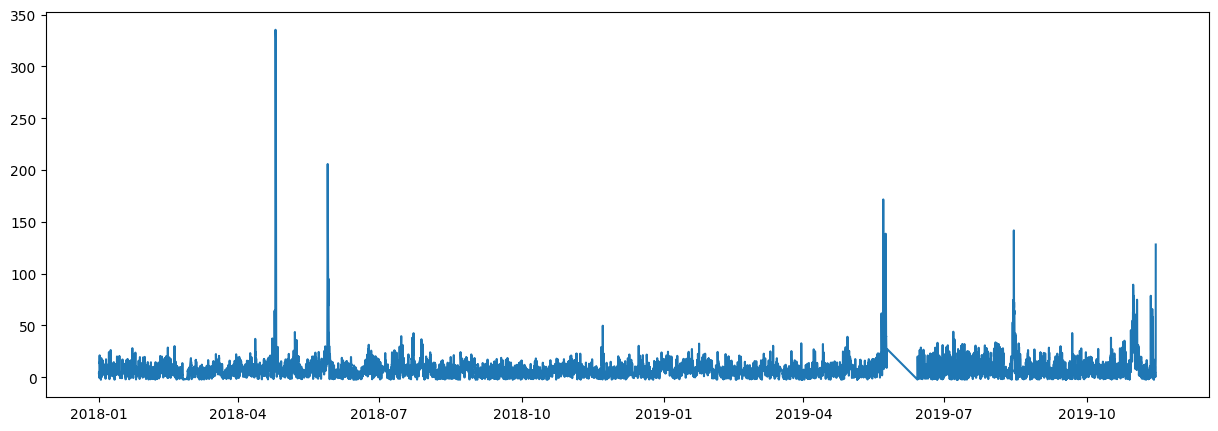

In [ ]:

plt.figure(figsize=(15,5))
plt.plot(pm25['datetime'], pm25['pm25'])
plt.show()

In [ ]:
fire = pd.read_csv("digital_earth_australia_hotspots_export_page_1 (1).csv")
print(fire.head())
print(fire.columns)


                                      FID       id satellite  \
0  hotspots.fid--c3c7bb0_1a0ebf944e7_3332  5870665     TERRA   
1  hotspots.fid--c3c7bb0_1a0ebf944e7_3333  5870230     TERRA   
2  hotspots.fid--c3c7bb0_1a0ebf944e7_3335  5837033     TERRA   
3  hotspots.fid--c3c7bb0_1a0ebf944e7_3336  5831823     TERRA   
4  hotspots.fid--c3c7bb0_1a0ebf944e7_3337  5832911     TERRA   

  satellite_nssdc_id satellite_operating_agency sensor  orbit  start_dt  \
0          1999-068A                       NASA  MODIS    NaN       NaN   
1          1999-068A                       NASA  MODIS    NaN       NaN   
2          1999-068A                       NASA  MODIS    NaN       NaN   
3          1999-068A                       NASA  MODIS    NaN       NaN   
4          1999-068A                       NASA  MODIS    NaN       NaN   

   stop_dt  filename  ...  latitude  longitude                 location  \
0      NaN       NaN  ...   -11.395    132.470   POINT (-11.395 132.47)   
1      NaN    

In [ ]:
fire = fire[[
'datetime',
'latitude',
'longitude',
'temp_kelvin',
'power',
'confidence'
]]

In [ ]:
fire['datetime'] = pd.to_datetime(
fire['datetime']
)

In [ ]:
fire['date'] = fire['datetime'].dt.date

In [ ]:
daily_fire = (
    fire.groupby('date')
    .agg(
        fire_count=('power', 'count'),
        total_power=('power', 'sum'),
        avg_temp=('temp_kelvin', 'mean')
    )
    .reset_index()
)

daily_fire.head()

,date,fire_count,total_power,avg_temp
0,2002-08-27,0,0.0,331.088431
1,2002-08-28,0,0.0,332.793564
2,2002-08-29,0,0.0,326.968182
3,2002-08-30,0,0.0,339.569986
4,2002-08-31,0,0.0,331.065451


In [ ]:
pm25['date'] = pm25['datetime'].dt.date

daily_pm25 = (
    pm25.groupby('date')
    .agg(pm25=('pm25', 'mean'))
    .reset_index()
)

daily_pm25.head()

,date,pm25
0,2018-01-01,9.445652
1,2018-01-02,6.004167
2,2018-01-03,8.795833
3,2018-01-04,6.141667
4,2018-01-05,6.110417


In [ ]:
df = pd.merge(daily_pm25, daily_fire, on='date', how='left')
df.head()


,date,pm25,fire_count,total_power,avg_temp
0,2018-01-01,9.445652,NaN,NaN,NaN
1,2018-01-02,6.004167,NaN,NaN,NaN
2,2018-01-03,8.795833,NaN,NaN,NaN
3,2018-01-04,6.141667,NaN,NaN,NaN
4,2018-01-05,6.110417,NaN,NaN,NaN


In [ ]:
df['fire_count'] = df['fire_count'].fillna(0)
df['total_power'] = df['total_power'].fillna(0)
df['avg_temp'] = df['avg_temp'].fillna(0)

df.head()

,date,pm25,fire_count,total_power,avg_temp
0,2018-01-01,9.445652,0.0,0.0,0.0
1,2018-01-02,6.004167,0.0,0.0,0.0
2,2018-01-03,8.795833,0.0,0.0,0.0
3,2018-01-04,6.141667,0.0,0.0,0.0
4,2018-01-05,6.110417,0.0,0.0,0.0


In [ ]:
df['pm25_lag1'] = df['pm25'].shift(1)
df['pm25_lag3'] = df['pm25'].shift(3)
df['pm25_lag7'] = df['pm25'].shift(7)

In [ ]:
df['target'] = df['pm25'].shift(-1)

In [ ]:
df = df.dropna()

In [ ]:
features = ['pm25_lag1', 'pm25_lag3', 'pm25_lag7', 'fire_count', 'total_power', 'avg_temp']

X = df[features]
y = df['target']

In [ ]:
split_index = int(len(df)*0.8)
X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBRegressor
model = XGBRegressor(
n_estimators=200,
max_depth=5,
learning_rate=0.05,
random_state=42
)
model.fit(X_train,y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
pred = model.predict(X_test)

In [ ]:
mae = mean_absolute_error(y_test,pred)
rmse = np.sqrt(
mean_squared_error(y_test,pred)
)
r2 = r2_score(y_test,pred)
print("MAE =",mae)
print("RMSE =",rmse)
print("R2 =",r2)

MAE = 5.972219685566278
RMSE = 10.869272762062446
R2 = -0.7638854295939153
